# 2026 신호 및 시스템 조별 챌린지
## 내 목소리를 구해줘!
*Speech Noise Reduction Challenge · 2026학년도 2학기*

잡음 속에 묻힌 목소리를 여러분의 알고리즘으로 되찾아 보세요.
수강생이 직접 녹음한 음성을 바탕으로, **푸리에 변환으로 잡음의 주파수 특성을 분석하고 음성은 보존하면서 잡음을 줄이는 것**이 목표입니다.
3인 이내의 팀으로 기본 필터부터 Spectral Subtraction, Wiener Filter, 딥러닝까지 탐구하며,
처리 전후의 소리와 스펙트로그램으로 어떤 변화가 생겼는지 설명해 보세요.

### 제출부터 리더보드까지

| 항목 | 안내 |
| :--- | :--- |
| **제출물** | **GitHub 링크와 AI 활용 내역서**를 매 제출마다 제출합니다. 팀의 GitHub 저장소에는 코드와 학습 가중치(해당 시)를 올리고, 조교가 접근하여 실행할 수 있도록 공개합니다. |
| **입출력 형식** | `input/` 폴더의 **모든 테스트 음성 파일**을 처리하여, 잡음을 제거한 음성을 `output/` 폴더에 저장해야 합니다. |
| **제출 방법** | **팀장**이 대표로 **런어스 → 질의응답 → 비밀글**에 **GitHub 링크와 해당 회차의 AI 활용 내역서**를 제출합니다. |
| **평가 및 순위** | 조교가 **히든 테스트셋**으로 평가하며, **PESQ가 높은 순서**로 순위를 매깁니다. 평가 결과는 **리더보드에 실시간으로 업데이트**됩니다. |
| **제출 횟수** | **주 1회**로 제한합니다. 챌린지 막바지에는 횟수 제한을 완화할 예정입니다. |

> 최초 1회 제출은 가급적 빠르게 진행하세요.
> 이후에는 제공된 **Validation 데이터셋**으로 성능을 비교하고, 가장 좋은 성능을 보인 알고리즘을 제출하는 것을 권장합니다.

생성형 AI 활용을 권장하되, 결과는 직접 검증하세요. **매 제출마다** 안내 자료의 양식에 따라 **AI 활용 내역서**를 작성합니다.
최초 제출에는 접근 방법과 검증 과정을, 이후 제출에는 이전 제출 대비 **알고리즘 개선을 위한 방법론의 변화, AI 활용 내용, 검증 결과**를 간략히 정리하세요.

---

### 이 노트북으로 시작하기

**Basic Filter · Spectral Subtraction · Wiener Filter**를 실행하고, 스펙트로그램·청취·SNR/PESQ로 비교하는 예제입니다.
Colab/Jupyter에서 위에서 아래로 실행하세요. **2절**에서 데이터 경로, **10절**에서 한 파일의 시각화·청취,
**12절**에서 전체 Validation 평가를 설정합니다. Clean 음성은 비교·평가에만 사용합니다.


## 1. 실행 환경

Colab에서는 아래 셀로 필요한 패키지를 설치합니다. 로컬 Jupyter에서는 같은 커널에 패키지를 설치해야 합니다.
`pesq==0.0.4`는 C 확장을 사용합니다. Windows에서 MSVC 오류가 나면 **Anaconda Prompt**에서 다음 환경을
만든 뒤 Jupyter를 실행하세요 (노트북 설치 셀은 이미 설치된 패키지를 건너뜁니다).

```bash
conda create -n denoise -c conda-forge python=3.12 numpy scipy pandas matplotlib pysoundfile pesq=0.0.4 notebook ipython tqdm
conda activate denoise
jupyter notebook
```

일반 pip 환경에서는 `pip install numpy scipy soundfile pandas matplotlib pesq IPython tqdm`도 사용할 수 있습니다.
패키지 교체 후 이미 import한 라이브러리가 있다면 커널을 재시작하세요.


In [1]:
# Make Conda DLLs available even when VS Code skips environment activation.
import os
import sys
from pathlib import Path

_conda_dll_handles = []
if sys.platform == "win32" and (Path(sys.prefix) / "conda-meta").is_dir():
    _conda_bin = Path(sys.prefix) / "Library" / "bin"
    if _conda_bin.is_dir():
        os.environ["PATH"] = str(_conda_bin) + os.pathsep + os.environ.get("PATH", "")
        _conda_dll_handles.append(os.add_dll_directory(str(_conda_bin)))

import importlib.util
import subprocess

dependencies = {
    "numpy": "numpy>=1.26,<3", "scipy": "scipy>=1.12,<2",
    "soundfile": "soundfile>=0.12,<1", "pandas": "pandas>=2.1,<4",
    "matplotlib": "matplotlib>=3.8,<4", "IPython": "ipython>=8,<10",
    "tqdm": "tqdm>=4.66,<5", "pesq": "pesq==0.0.4", "ipywidgets": "ipywidgets>=8,<9",
}
missing = [package for module, package in dependencies.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing), flush=True)
    result = subprocess.run([sys.executable, "-m", "pip", "install", *missing])
    if result.returncode:
        if sys.platform == "win32" and "pesq==0.0.4" in missing:
            command = subprocess.list2cmdline([
                "conda", "install", "--prefix", sys.prefix, "-c", "conda-forge",
                "pesq=0.0.4", "pysoundfile", "pandas>=2.1,<4", "tqdm>=4.66,<5",
            ])
            print("If PESQ compilation fails on Windows, run in Anaconda Prompt:")
            print(command)
            print("After installation, restart the notebook kernel and run from the first cell.")
        raise RuntimeError("Package installation failed. Check the pip error above and the setup instructions.")
print("Python:", sys.version.split()[0])


Python: 3.14.4


## 2. 데이터 경로와 설정

`DATA_SOURCE="local"`은 `release/noise_reduction_challenge`을 현재 폴더와 상위 폴더에서 찾습니다.
`"google_drive"`는 Colab에서 Drive를 연결하고 `/content/drive/MyDrive/noise_reduction_challenge`을 사용합니다.
Colab에서는 `DATA_SOURCE="google_drive"`로 설정하고, 압축을 푼 폴더 전체를 내 드라이브에 올리세요.
로컬에서는 압축 해제 위치에서도 기본 경로를 자동 탐색합니다.
각 split의 `samples.csv`는 파일 대응·잡음별 선택·평가에 필요한 목록이므로 함께 보관하세요.
데이터 위치가 다르면 아래 경로를 수정하세요. 알고리즘 파라미터는 `CFG = Config(...)`에서 변경합니다.

블록도는 `DATA_ROOT / "figures"`의 PNG 파일을 불러옵니다. Colab에서도 **figures를 포함한 폴더 전체**를 Drive에 올리세요. 전체 과정 그림은 경로 설정 직후에 표시됩니다.


In [2]:
DATA_SOURCE = "local"  # "local" 또는 "google_drive"
LOCAL_DATA_PATH = Path("release/noise_reduction_challenge")
GOOGLE_DRIVE_DATA_PATH = Path("/content/drive/MyDrive/noise_reduction_challenge")
GOOGLE_DRIVE_MOUNT_PATH = "/content/drive"
EXPORT_ALL_AUDIO = False  # True: train/validation 전체의 처리 결과 WAV도 저장
EVALUATE_BASIC_VARIANTS = True  # 개별 LP/HP/BS 평가를 추가 (대표 3종은 항상 평가)


라이브러리와 파라미터를 정의합니다.


In [3]:
from dataclasses import dataclass, asdict
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import soundfile as sf
from scipy import signal
from scipy.ndimage import uniform_filter1d
from tqdm.auto import tqdm


@dataclass(frozen=True)
class Config:
    sample_rate: int = 16000
    n_fft: int = 512
    hop: int = 128
    filter_order: int = 4
    lowpass_hz: float = 3500.0
    highpass_hz: float = 100.0
    bandstop_hz: tuple = (950.0, 1050.0)
    basic_stages: tuple = ("highpass", "lowpass", "bandstop")
    noise_fraction: float = 0.20
    subtraction_alpha: float = 1.5
    subtraction_floor: float = 0.02
    wiener_smoothing: float = 0.98
    wiener_gain_floor: float = 0.05

    def __post_init__(self):
        if self.sample_rate != 16000:
            raise ValueError("This baseline uses 16000 Hz / wideband PESQ.")
        if not 0 < self.hop <= self.n_fft or self.n_fft < 4:
            raise ValueError("Require 0 < hop <= n_fft and n_fft >= 4.")
        if not signal.check_NOLA("hann", self.n_fft, self.n_fft - self.hop):
            raise ValueError("STFT window/hop does not satisfy NOLA.")
        if not 0 < self.noise_fraction <= 1:
            raise ValueError("noise_fraction must be in (0, 1].")
        if not 0 <= self.wiener_smoothing < 1:
            raise ValueError("wiener_smoothing must be in [0, 1).")
        if not 0 <= self.subtraction_floor <= 1 or self.subtraction_alpha < 0:
            raise ValueError("Invalid spectral subtraction parameters.")
        if not 0 <= self.wiener_gain_floor <= 1:
            raise ValueError("wiener_gain_floor must be in [0, 1].")
        nyquist = self.sample_rate / 2
        if not 0 < self.highpass_hz < self.lowpass_hz < nyquist:
            raise ValueError("Require 0 < highpass < lowpass < Nyquist.")
        if not 0 < self.bandstop_hz[0] < self.bandstop_hz[1] < nyquist:
            raise ValueError("Invalid band-stop interval.")
        if self.filter_order < 1 or int(self.filter_order) != self.filter_order:
            raise ValueError("filter_order must be a positive integer.")
        if any(s not in ("lowpass", "highpass", "bandstop") for s in self.basic_stages):
            raise ValueError("Unknown basic filter stage.")


CFG = Config()


def waveform(x):
    x = np.asarray(x, dtype=np.float64)
    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError("Expected a nonempty, finite mono waveform.")
    return x


각 split의 `samples.csv`에서 clean/noisy 쌍을 읽고, 경로·길이·표본률을 검증합니다.


In [4]:
def resolve_local_data_path(data_path="release/noise_reduction_challenge", start=None):
    """Resolve an explicit local path from the working folder or its parents."""
    data_path = Path(data_path).expanduser()
    start = Path(start or Path.cwd()).resolve()
    candidates = ([data_path] if data_path.is_absolute() else
                  [parent / data_path for parent in (start, *start.parents)])
    # The default also works after extracting the folder outside this workspace.
    if data_path == Path("release/noise_reduction_challenge"):
        for parent in (start, *start.parents):
            candidates.extend((parent, parent / "noise_reduction_challenge"))
    for candidate in candidates:
        if all((candidate / split / "samples.csv").is_file()
               for split in ("train", "validation")):
            return candidate.resolve()
    raise FileNotFoundError(
        f"LOCAL_DATA_PATH={str(data_path)!r} could not be found from {start}. "
        "Set it to the folder containing train and validation, each with samples.csv."
    )




def load_manifest(root, split):
    if split not in ("train", "validation"):
        raise ValueError("split must be train or validation")
    root = Path(root).resolve()
    df = pd.read_csv(root / split / "samples.csv")
    required = {"segment_id", "clean_path", "noisy_path", "sample_rate_hz", "num_samples",
                "noise_category", "noise_collection", "noise_code", "noise_difficulty",
                "target_snr_db", "split"}
    if not required.issubset(df.columns) or df.empty:
        raise ValueError("Empty manifest or required columns missing.")
    if df.segment_id.duplicated().any():
        raise ValueError("Duplicate segment IDs.")
    if "split" in df and not df["split"].eq(split).all():
        raise ValueError("Manifest split mismatch.")
    for column in ("clean_path", "noisy_path"):
        for relative in df[column]:
            path = (root / relative).resolve()
            if not path.is_relative_to(root) or not path.is_file():
                raise FileNotFoundError(f"Invalid/missing file: {path}")
    return df


def read_audio(root, row, kind, cfg=CFG):
    x, sr = sf.read(Path(root) / row[f"{kind}_path"], dtype="float64")
    x = waveform(x)
    if sr != cfg.sample_rate or sr != int(row["sample_rate_hz"]):
        raise ValueError(f"Sample-rate mismatch for {row['segment_id']}: {sr}")
    if x.size != int(row["num_samples"]):
        raise ValueError(f"Length mismatch for {row['segment_id']}")
    return x


def read_pair(root, row, cfg=CFG):
    return read_audio(root, row, "clean", cfg), read_audio(root, row, "noisy", cfg)


def read_audio_file(path, cfg=CFG, data_root=None):
    """Read exactly one file; relative paths use data_root, or the working folder."""
    path = Path(path).expanduser()
    if not path.is_absolute() and data_root is not None:
        path = Path(data_root) / path
    path = path.resolve()
    x, sample_rate = sf.read(path, dtype="float64")
    if sample_rate != cfg.sample_rate:
        raise ValueError(f"Expected {cfg.sample_rate} Hz, got {sample_rate} Hz: {path}")
    return waveform(x), path




def select_examples(manifest, noise_category=None, noise_code=None,
                    target_snr_db=None, noise_difficulty=None):
    """Select metadata rows only. None means all values; no waveform is processed."""
    selected = manifest.copy()
    for column, value in (("noise_category", noise_category), ("noise_code", noise_code),
                           ("noise_difficulty", noise_difficulty)):
        if value is not None:
            selected = selected[selected[column].eq(value)]
    if target_snr_db is not None:
        selected = selected[np.isclose(selected.target_snr_db, float(target_snr_db))]
    return selected.sort_values("segment_id").reset_index(drop=True)


In [5]:
if DATA_SOURCE == "local":
    DATA_ROOT = resolve_local_data_path(LOCAL_DATA_PATH)
elif DATA_SOURCE == "google_drive":
    try:
        from google.colab import drive
    except ImportError as error:
        raise RuntimeError(
            "google_drive 모드는 Colab에서 실행하세요. "
            "로컬 Drive 동기화 폴더는 local 모드와 LOCAL_DATA_PATH를 사용하세요."
        ) from error
    drive.mount(GOOGLE_DRIVE_MOUNT_PATH)
    DATA_ROOT = GOOGLE_DRIVE_DATA_PATH.expanduser().resolve()
else:
    raise ValueError('DATA_SOURCE는 "local" 또는 "google_drive"여야 합니다.')

OUTPUT_ROOT = DATA_ROOT / "outputs"
train_df = load_manifest(DATA_ROOT, "train")
validation_df = load_manifest(DATA_ROOT, "validation")
print("DATA_SOURCE:", DATA_SOURCE)
print("DATA_ROOT:", DATA_ROOT)
print(f"Train: {len(train_df)} files / Validation: {len(validation_df)} files")
print(asdict(CFG))


DATA_SOURCE: local
DATA_ROOT: /Users/itaegyeong/Desktop/noise_reduction_challenge
Train: 1296 files / Validation: 164 files
{'sample_rate': 16000, 'n_fft': 512, 'hop': 128, 'filter_order': 4, 'lowpass_hz': 3500.0, 'highpass_hz': 100.0, 'bandstop_hz': (950.0, 1050.0), 'basic_stages': ('highpass', 'lowpass', 'bandstop'), 'noise_fraction': 0.2, 'subtraction_alpha': 1.5, 'subtraction_floor': 0.02, 'wiener_smoothing': 0.98, 'wiener_gain_floor': 0.05}


## Speech Enhancement 전체 과정


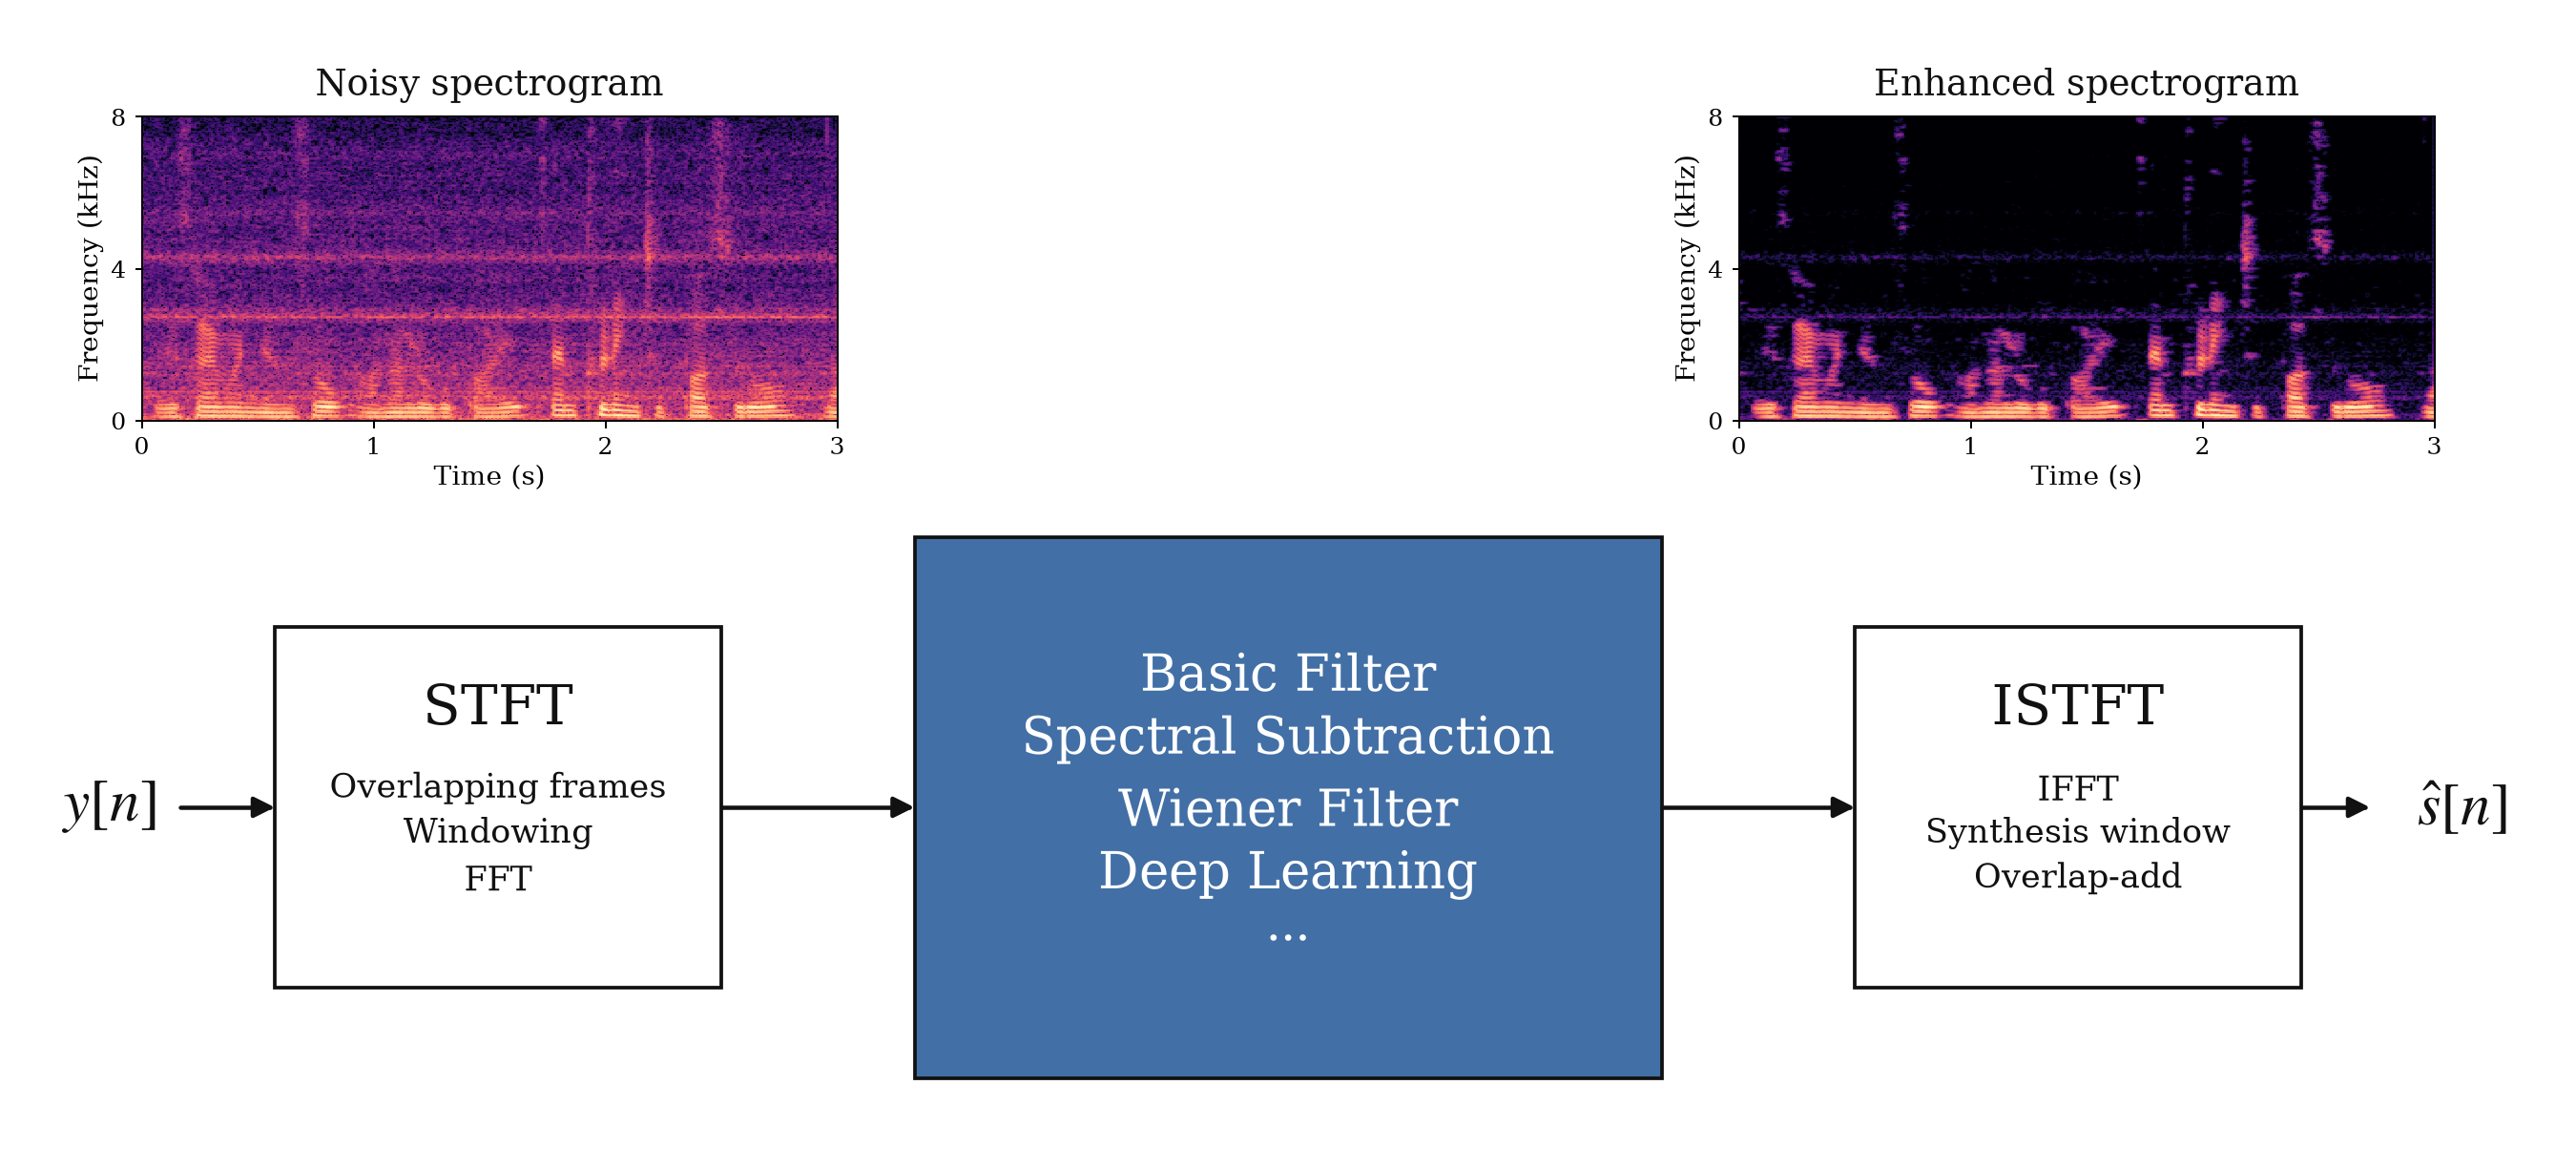

In [6]:
from IPython.display import Image, display
figure_path = DATA_ROOT / "figures" / "speech_enhancement.png"
if not figure_path.is_file():
    raise FileNotFoundError(f"그림 파일을 찾을 수 없습니다: {figure_path}. 배포 폴더의 figures도 함께 복사하세요.")
display(Image(filename=str(figure_path), width=1000))


**STFT(Short-Time Fourier Transform, 단시간 푸리에 변환)**는 음성을 서로 겹치는 짧은 프레임으로 나누고, 각 프레임에 창 함수를 적용한 뒤 FFT를 계산합니다. 전체 음성에 FFT를 한 번 적용하면 주파수 성분이 언제 나타나는지 알기 어렵지만, STFT는 시간에 따라 달라지는 음성과 잡음을 구간별로 분석·처리할 수 있습니다. **ISTFT**는 프레임별 IFFT와 창 적용 후 overlap-add 및 정규화로 파형을 복원합니다.

파란 블록의 알고리즘은 선택 후보입니다. 현재 Basic Filter는 시간 영역에서 직접 처리하며, Deep Learning은 모델에 따라 처리 영역이 달라집니다.

위 스펙트로그램은 Validation 첫 샘플의 입력과 Wiener Filter 기본값 처리 결과를 동일한 색상·dB 기준으로 표시한 고정 예시입니다. **Enhanced는 추정 결과이며 Clean 정답이 아닙니다.**


### 3. 기본 필터


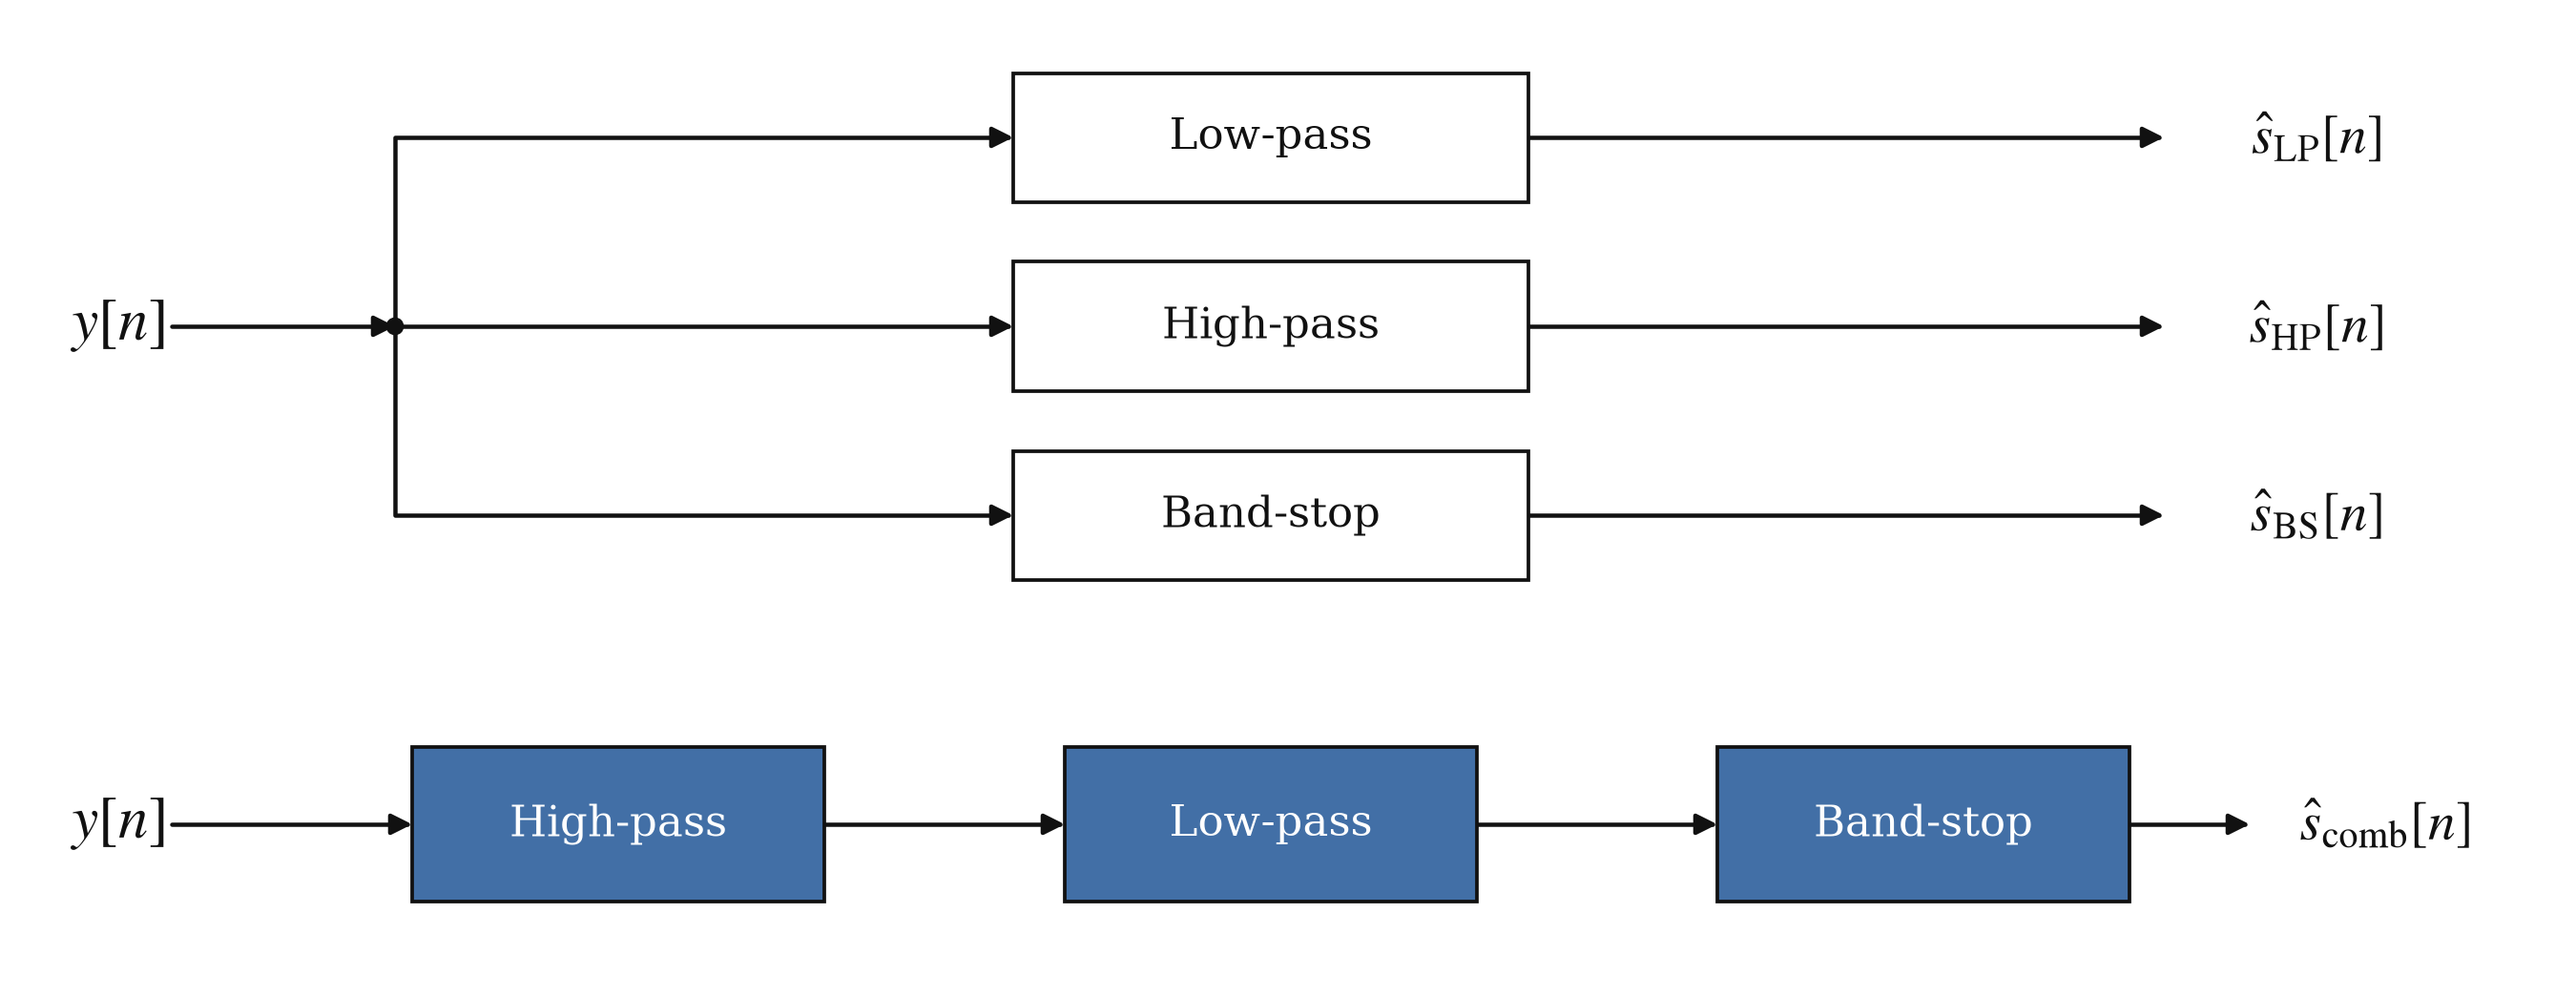

In [26]:
from IPython.display import Image, display
figure_path = DATA_ROOT / "figures" / "basic_filter.png"
if not figure_path.is_file():
    raise FileNotFoundError(f"그림 파일을 찾을 수 없습니다: {figure_path}. 배포 폴더의 figures도 함께 복사하세요.")
display(Image(filename=str(figure_path), width=1000))


LP·HP·BS는 각각 독립적으로 실행하며, 아래쪽 HP → LP → BS는 추가 비교용 조합입니다.
Butterworth SOS 필터를 순방향·역방향으로 적용하는 오프라인 처리입니다.

대역은 `Config.highpass_hz`, `lowpass_hz`, `bandstop_hz`를 따릅니다. 차단 대역이 음성과 겹치면 음성도 감쇠됩니다.
양방향 처리의 크기 응답은 단방향 응답의 제곱이므로 설정 차단 주파수에서 약 −6 dB입니다.


In [27]:
def basic_filter(noisy, kind="combined", cfg=CFG):
    """Butterworth SOS, forward/backward filtering (offline, zero phase)."""
    y = waveform(noisy).copy()
    stages = cfg.basic_stages if kind == "combined" else (kind,)
    cutoffs = {"lowpass": cfg.lowpass_hz, "highpass": cfg.highpass_hz,
               "bandstop": cfg.bandstop_hz}
    for stage in stages:
        if stage not in cutoffs:
            raise ValueError(f"Unknown filter: {stage}")
        sos = signal.butter(cfg.filter_order, cutoffs[stage], btype=stage,
                            fs=cfg.sample_rate, output="sos")
        # The usual padding, bounded for very short input signals.
        ntaps = 2 * len(sos) + 1 - min((sos[:, 2] == 0).sum(), (sos[:, 5] == 0).sum())
        y = signal.sosfiltfilt(sos, y, padlen=min(3 * int(ntaps), len(y) - 1))
    return y


### 4. 공통 STFT와 잡음 추정

Hann 창(512 samples), hop 128 samples로 STFT를 계산합니다.
경계 padding을 제외한 완전한 프레임 중 저에너지 20%의 평균 파워를 3-bin 평활화하여 잡음 PSD를 추정합니다.
잡음 PSD는 파일별로 고정하며 clean은 사용하지 않습니다. 무음 검출기는 아니므로 연속 발화·변동 잡음에서는 추정 오차가 생길 수 있습니다.


---파라미터 튜닝---, 불연속 겹쳐서하고 인벌스애서 빼줘야함? 얼마나 겹치는지에 대한 지표이니 

In [ ]:
def stft_audio(x, cfg=CFG):
    x = waveform(x)
    if x.size < cfg.n_fft:
        x = np.pad(x, (0, cfg.n_fft - x.size))
    return signal.stft(x, fs=cfg.sample_rate, window="hann", nperseg=cfg.n_fft,
                       noverlap=cfg.n_fft - cfg.hop, nfft=cfg.n_fft,
                       boundary="zeros", padded=True)


def inverse_stft(z, length, cfg=CFG):
    _, y = signal.istft(z, fs=cfg.sample_rate, window="hann", nperseg=cfg.n_fft,
                        noverlap=cfg.n_fft - cfg.hop, nfft=cfg.n_fft,
                        input_onesided=True, boundary=True)
    if len(y) < length:
        raise ValueError("Inverse STFT produced insufficient samples.")
    return waveform(y[:length])


def estimate_noise_power(z, times, length, cfg=CFG):
    """Average the lowest-energy complete frames; no clean/reference access."""
    power = np.abs(z) ** 2 
    # Avoid selecting artificially quiet frames introduced by boundary padding.
    centers = np.rint(times * cfg.sample_rate).astype(int)
    full = np.flatnonzero((centers >= cfg.n_fft // 2) &
                          (centers + cfg.n_fft // 2 <= length))
    if not len(full):
        full = np.arange(power.shape[1])
    energy = power[:, full].mean(axis=0)
    count = max(1, int(np.ceil(cfg.noise_fraction * len(full)))) # ---noise_fraction 중요한 변수이다.--- 잡음만 있는 구간에서 지금은 0.2로 되어있는데 하위 노이즈 어쩌고
    selected = full[np.argsort(energy, kind="stable")[:count]]
    estimate = power[:, selected].mean(axis=1)
    return np.maximum(uniform_filter1d(estimate, size=3, mode="nearest"), 1e-18)


### 5. Spectral Subtraction


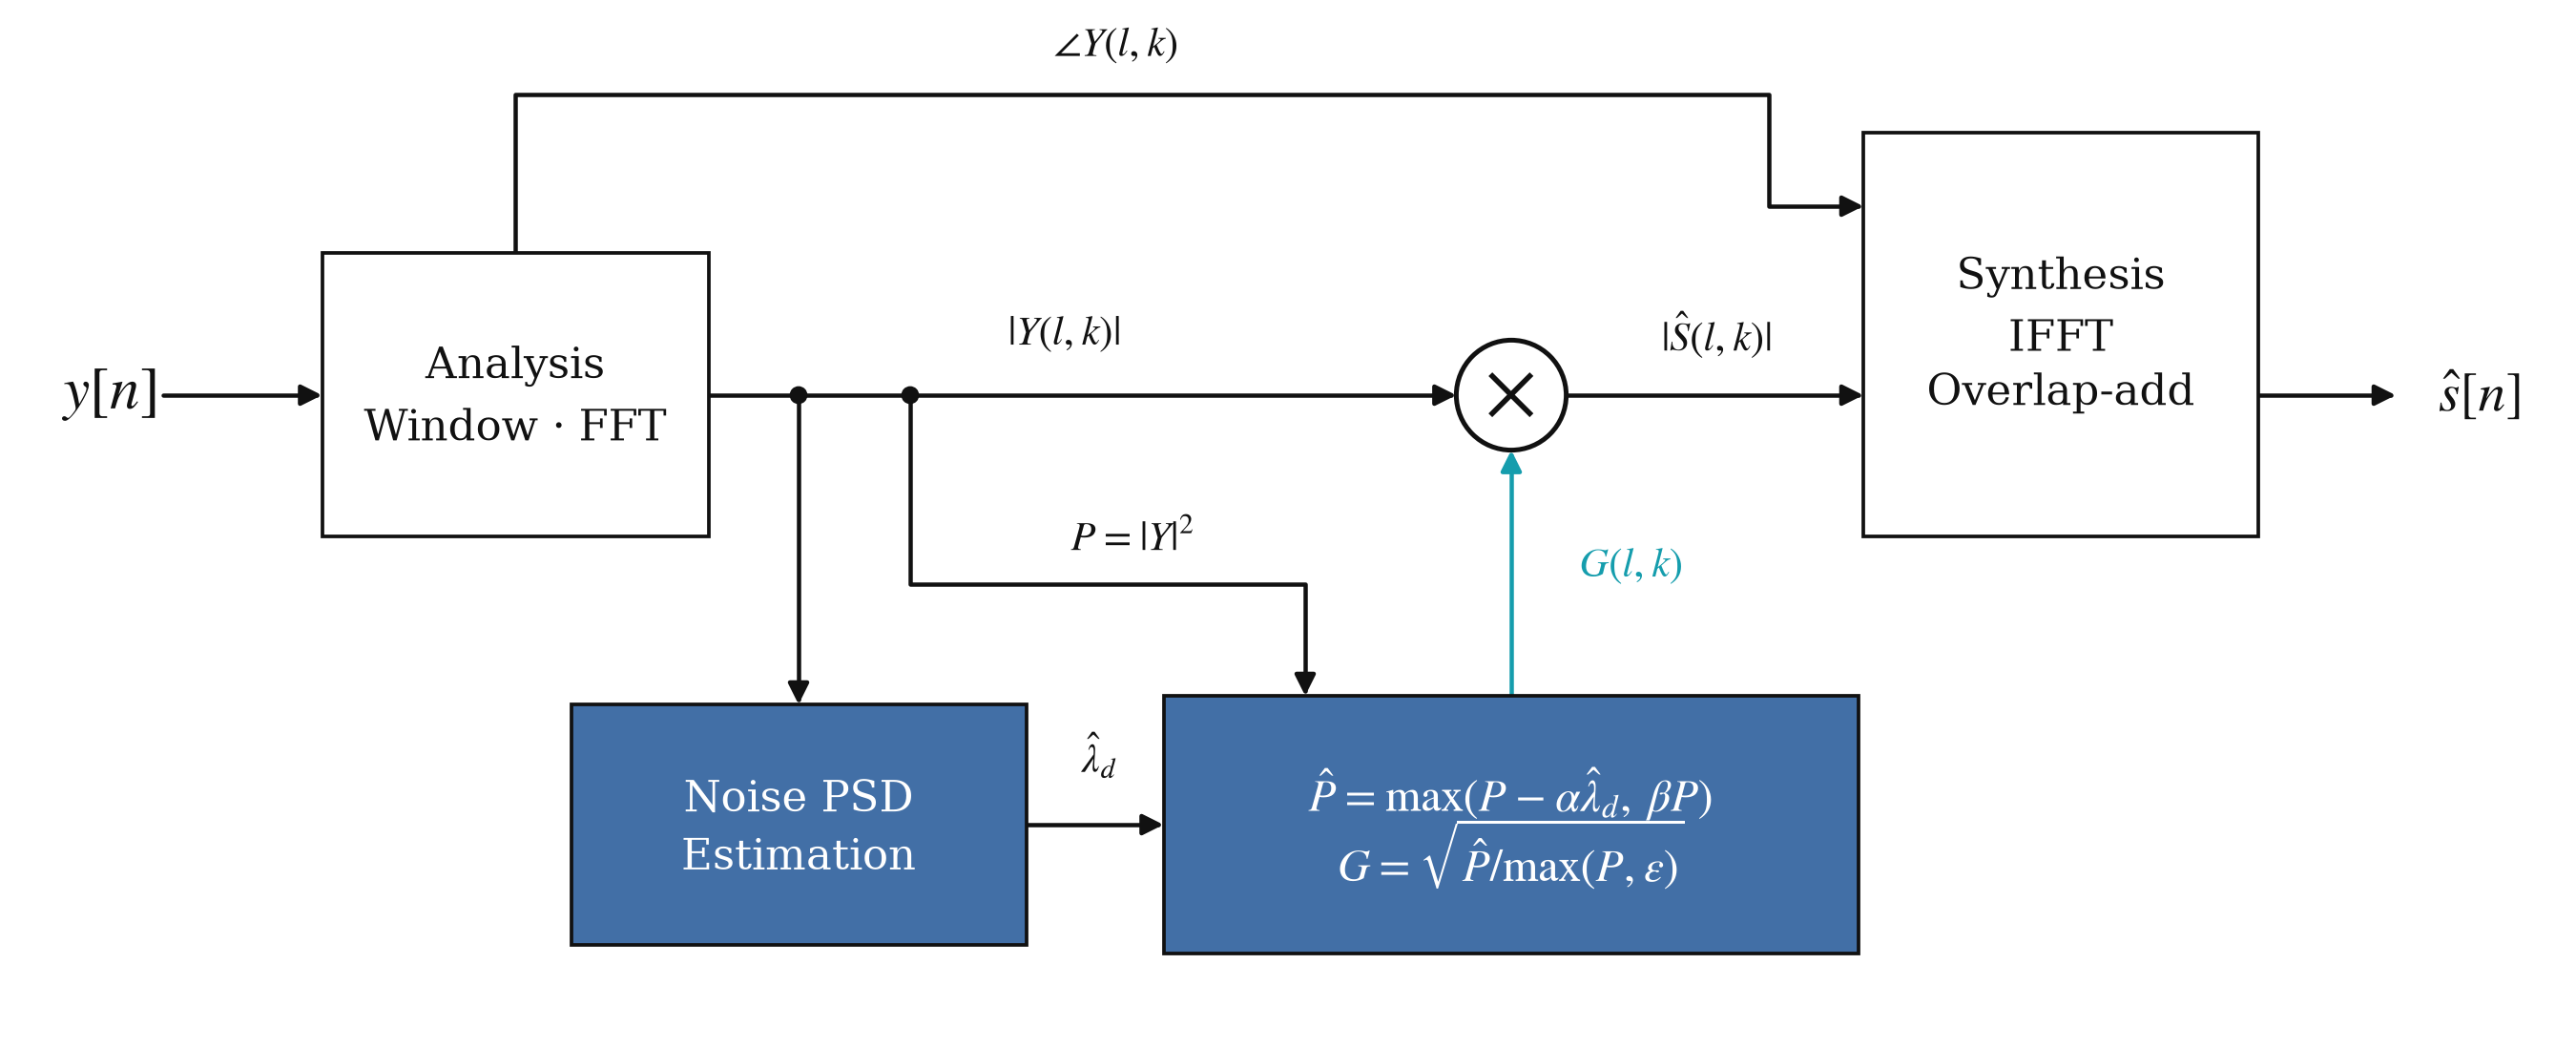

In [29]:
from IPython.display import Image, display
figure_path = DATA_ROOT / "figures" / "spectral_subtraction.png"
if not figure_path.is_file():
    raise FileNotFoundError(f"그림 파일을 찾을 수 없습니다: {figure_path}. 배포 폴더의 figures도 함께 복사하세요.")
display(Image(filename=str(figure_path), width=1000))


<sub>Reference: S. F. Boll, “Suppression of Acoustic Noise in Speech Using Spectral Subtraction,” IEEE TASSP, 27(2), 113–120, 1979. [PDF](https://course.ece.cmu.edu/~ece491/homework/Boll79.pdf)</sub>

입력 파워 $P=|Y|^2$에서 추정 잡음 파워 $N=\hat{\lambda}_d$를 차감합니다.
$\hat P=\max(P-\alpha N,\beta P)$로 하한을 두고, $G=\sqrt{\hat P/\max(P,\epsilon)}$를 적용한 뒤 입력 위상으로 복원합니다.

기본값은 $\alpha=1.5$, $\beta=0.02$입니다. 하한은 잡음 파워가 아닌 **입력 파워** 기준입니다.


In [30]:
def spectral_subtraction(noisy, cfg=CFG):
    x = waveform(noisy)
    _, times, z = stft_audio(x, cfg)
    power = np.abs(z) ** 2
    noise = estimate_noise_power(z, times, len(x), cfg)[:, None]
    # Power subtraction; keep the observed phase and bound gain by one.
    target = np.maximum(power - cfg.subtraction_alpha * noise,
                        cfg.subtraction_floor * power)
    gain = np.sqrt(np.clip(target / np.maximum(power, 1e-18), 0, 1))
    return inverse_stft(gain * z, len(x), cfg)


### 6. Wiener Filter


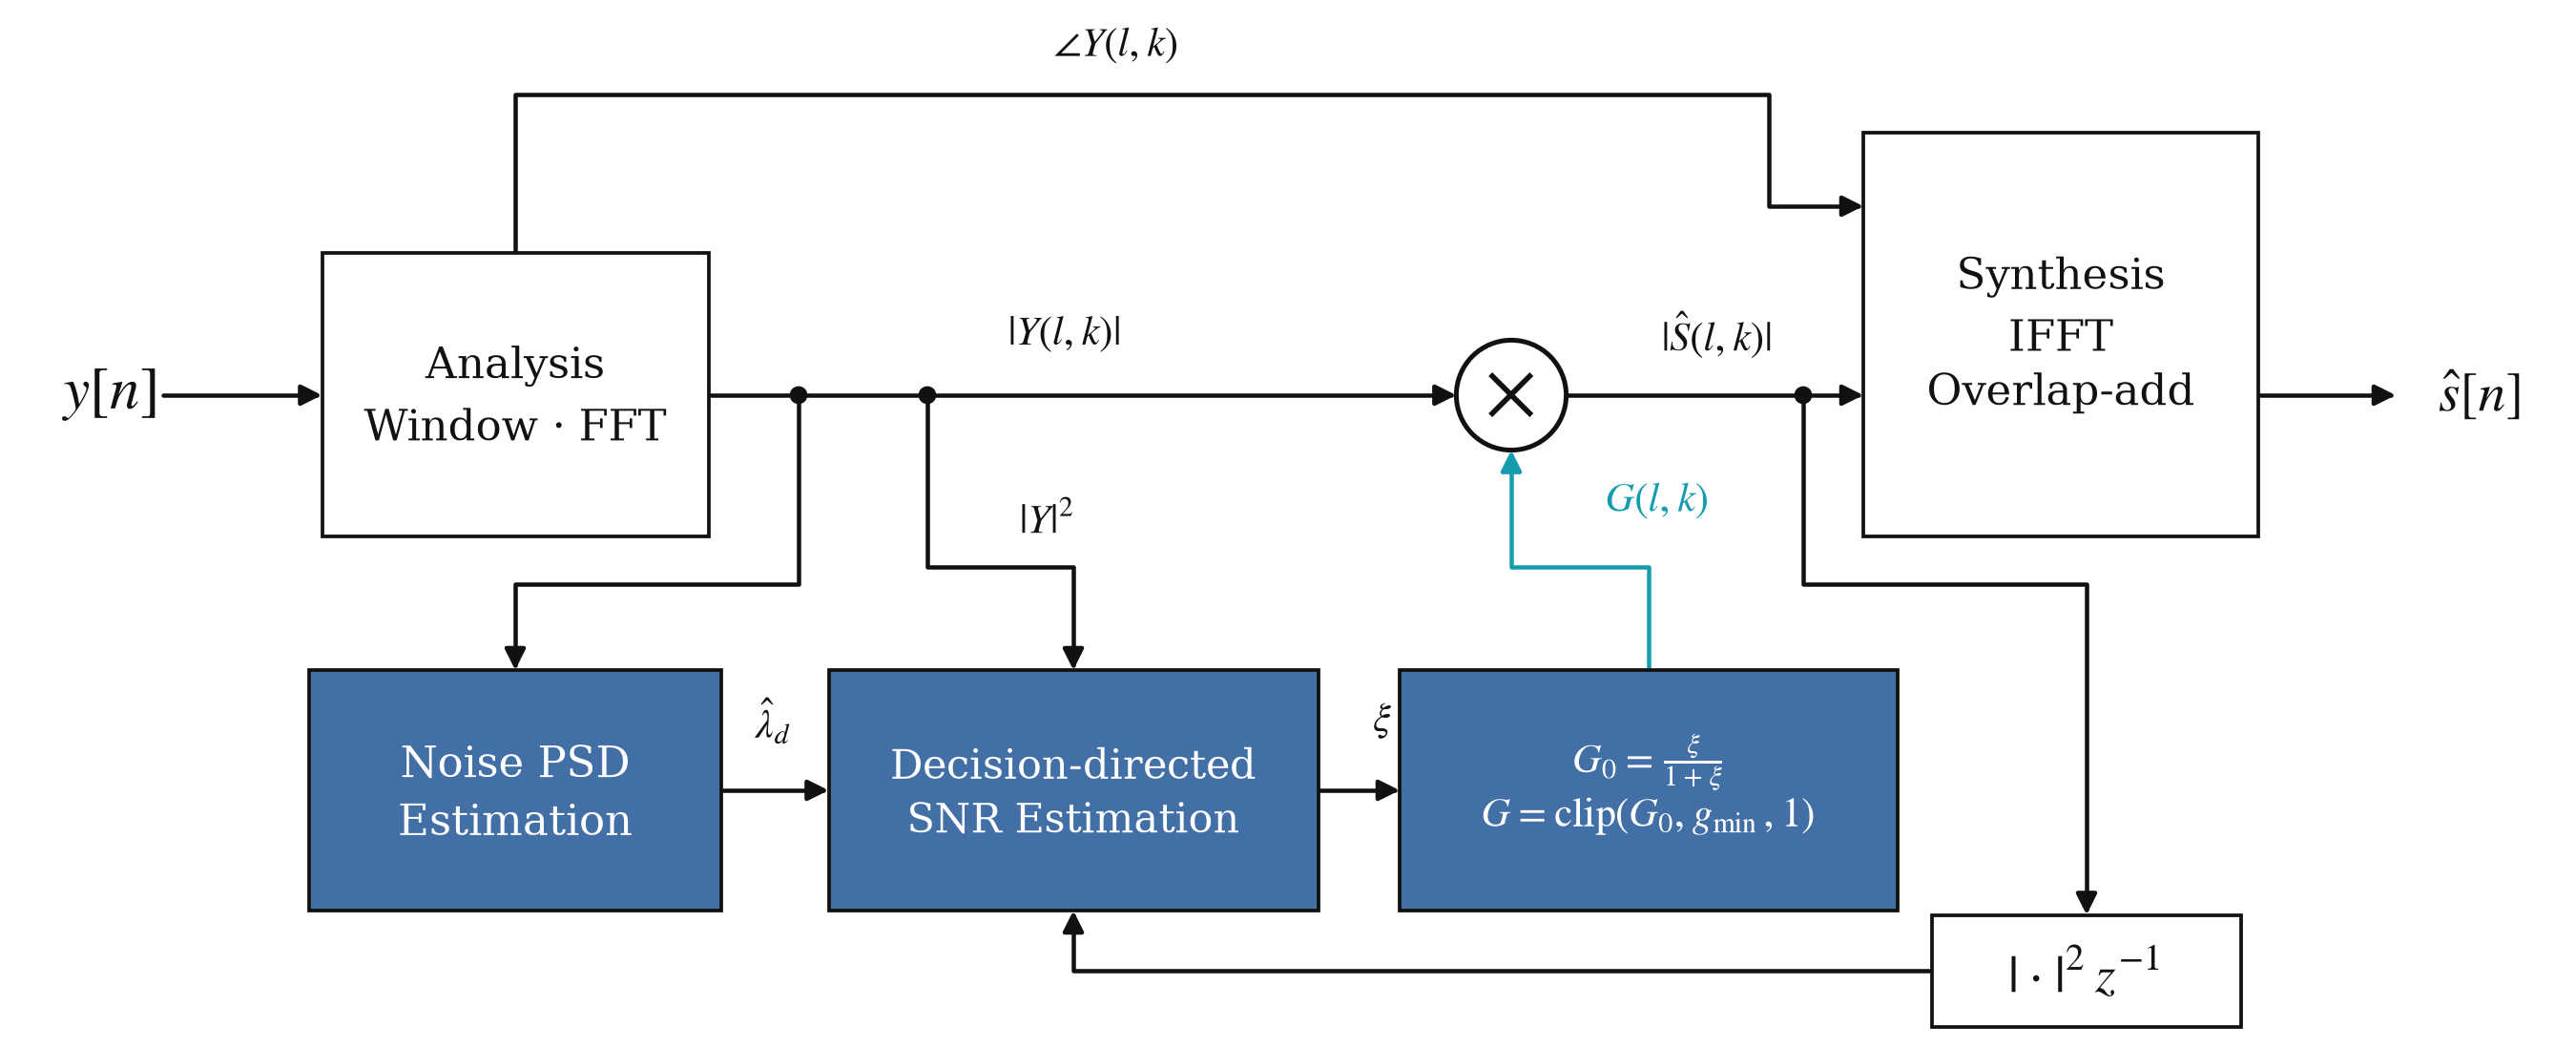

In [31]:
from IPython.display import Image, display
figure_path = DATA_ROOT / "figures" / "wiener_filter.png"
if not figure_path.is_file():
    raise FileNotFoundError(f"그림 파일을 찾을 수 없습니다: {figure_path}. 배포 폴더의 figures도 함께 복사하세요.")
display(Image(filename=str(figure_path), width=1000))


<sub>Reference (decision-directed SNR estimation): Y. Ephraim and D. Malah, “Speech Enhancement Using a Minimum Mean-Square Error Short-Time Spectral Amplitude Estimator,” IEEE TASSP, 32(6), 1109–1121, 1984. [PDF](https://malah.net.technion.ac.il/files/2017/08/Ephraim_Speech_Enhancement_ASSP84.pdf)</sub>

현재 입력과 이전 프레임의 처리 결과로 사전 SNR을 추정합니다.
$\gamma_t=P_t/N$, $\xi_t=a|\hat S_{t-1}|^2/N+(1-a)\max(\gamma_t-1,0)$이며,
$G_t=\mathrm{clip}(\xi_t/(1+\xi_t),g_{\min},1)$을 적용합니다.

기본값은 $a=0.98$, $g_{\min}=0.05$입니다. 첫 프레임은 $\max(\gamma_0-1,0)$로 초기화합니다.
그림의 $z^{-1}$은 한 프레임 지연을 뜻합니다.


In [32]:
def wiener_filter(noisy, cfg=CFG):
    x = waveform(noisy)
    _, times, z = stft_audio(x, cfg)
    power = np.abs(z) ** 2
    noise = estimate_noise_power(z, times, len(x), cfg)
    posterior_snr = power / noise[:, None]
    enhanced = np.empty_like(z)
    previous_clean_power = np.zeros_like(noise)
    for frame in range(z.shape[1]):
        instantaneous = np.maximum(posterior_snr[:, frame] - 1.0, 0.0)
        if frame == 0:
            prior_snr = instantaneous
        else:
            prior_snr = (cfg.wiener_smoothing * previous_clean_power / noise
                         + (1 - cfg.wiener_smoothing) * instantaneous)
        gain = np.clip(prior_snr / (1 + prior_snr), cfg.wiener_gain_floor, 1)
        enhanced[:, frame] = gain * z[:, frame]
        previous_clean_power = np.abs(enhanced[:, frame]) ** 2
    return inverse_stft(enhanced, len(x), cfg)


def enhance(noisy, cfg=CFG, include_basic_variants=False):
    outputs = {"basic_filter": basic_filter(noisy, cfg=cfg),
               "spectral_subtraction": spectral_subtraction(noisy, cfg),
               "wiener_filter": wiener_filter(noisy, cfg)}
    if include_basic_variants:
        for kind in ("lowpass", "highpass", "bandstop"):
            outputs[kind] = basic_filter(noisy, kind, cfg)
    for name, output in outputs.items():
        if waveform(output).shape != np.asarray(noisy).shape:
            raise ValueError(f"Invalid output shape: {name}")
    return outputs


### 7. 경로 하나로 추론·시각화·청취

`show_example(noisy_path, clean_path=None, cfg=CFG, data_root=DATA_ROOT)`는 파일 하나를 처리하고 스펙트로그램·재생 버튼을 표시합니다.
상대 경로는 `DATA_ROOT` 기준이며 입력은 mono/16 kHz입니다. Clean은 선택적 비교용입니다.
모든 출력은 같은 dB 기준과 재생 gain을 사용합니다. 배열만 필요하면 `infer_file(...)`을 사용하세요.


In [33]:
def infer_file(noisy_path, cfg=CFG, data_root=None, include_basic_variants=True):
    """Infer one noisy file, without plotting, a clean reference or any batch loop."""
    noisy, _ = read_audio_file(noisy_path, cfg, data_root)
    return {"noisy_input": noisy, **enhance(noisy, cfg, include_basic_variants)}


def show_example(noisy_path, clean_path=None, cfg=CFG, data_root=None,
                 include_basic_variants=True, verbose=True):
    """Infer and display one input file. clean_path is optional and comparison-only."""
    import matplotlib.pyplot as plt
    from IPython.display import Audio, Markdown, display

    from time import perf_counter
    started = perf_counter()
    if verbose:
        print("[1/3] Reading audio and running filters...", flush=True)
    outputs = infer_file(noisy_path, cfg, data_root, include_basic_variants)
    noisy = outputs["noisy_input"]
    if clean_path is not None:
        clean, _ = read_audio_file(clean_path, cfg, data_root)
        if clean.shape != noisy.shape:
            raise ValueError("Clean and noisy files must have the same length.")
        outputs = {"clean_reference": clean, **outputs}
    if verbose:
        print(f"[2/3] Building spectrograms ({perf_counter() - started:.2f}s)...", flush=True)
    label = Path(noisy_path).name
    reference_magnitude = max(float(np.abs(stft_audio(noisy, cfg)[2]).max()), 1e-12)
    fig, axes = plt.subplots(len(outputs), 1, figsize=(12, 2.15 * len(outputs)),
                             sharex=True, sharey=True, constrained_layout=True)
    for ax, (name, y) in zip(axes, outputs.items()):
        frequencies, times, z = stft_audio(y, cfg)
        db = 20 * np.log10(np.maximum(np.abs(z), 1e-12) / reference_magnitude)
        mesh = ax.pcolormesh(times, frequencies / 1000, db, shading="auto",
                             cmap="magma", vmin=-80, vmax=0)
        ax.set(title=name, ylabel="Frequency (kHz)")
    axes[-1].set_xlabel("Time (s)")
    fig.suptitle(f"{label} | shared dB reference: noisy peak")
    fig.colorbar(mesh, ax=list(axes), label="dB relative to noisy STFT peak")
    # Publish directly: GUI backends can block in plt.show().
    try:
        display(fig)
    finally:
        plt.close(fig)
    if verbose:
        print(f"[3/3] Building audio players ({perf_counter() - started:.2f}s)...", flush=True)
    # A single playback gain preserves level differences across all methods.
    playback_gain = 0.99 / max(1.0, max(float(np.abs(y).max()) for y in outputs.values()))
    display(Markdown(f"**{label}** — 공통 재생 gain: {playback_gain:.4f}"))
    for name, y in outputs.items():
        display(Markdown(f"**{name}**"))
        display(Audio(y * playback_gain, rate=cfg.sample_rate, normalize=False))
    if verbose:
        print(f"Done ({perf_counter() - started:.2f}s).", flush=True)
    return outputs


### 8. 전체 샘플 테스트 함수

`test_all_samples(DATA_ROOT, split="validation", cfg=CFG)`는 manifest 전체를 평가합니다.
`split="train"` 또는 `"all"`도 가능하며, `all`은 split별로 집계합니다.

$\mathrm{SNR}=10\log_{10}(\sum s[n]^2/\sum(s[n]-\hat{s}[n])^2)$, PESQ는 16 kHz wideband입니다.
정규화·시간 정렬 없이 파일별 점수를 평균하며, PESQ 실패는 원인과 개수를 별도 기록합니다.


PESQ가 높으면 높을수록 좋다.

In [34]:
def snr_db(clean, estimate):
    clean, estimate = waveform(clean), waveform(estimate)
    if clean.shape != estimate.shape:
        raise ValueError("SNR requires equal lengths.")
    energy = np.sum(clean ** 2)
    if energy <= 0:
        raise ValueError("SNR is undefined for a silent reference.")
    error = np.sum((clean - estimate) ** 2)
    return float(np.inf if error == 0 else 10 * np.log10(energy / error))


def pesq_score(clean, estimate, sample_rate=16000):
    from pesq import pesq, PesqError
    try:
        value = float(pesq(sample_rate, clean, estimate, mode="wb",
                           on_error=PesqError.RAISE_EXCEPTION))
        if not np.isfinite(value) or value < 0:
            raise ValueError(f"Invalid PESQ return value: {value}")
        return value, ""
    except (PesqError, ValueError) as error:
        return np.nan, f"{type(error).__name__}: {error}"


def summarize_scores(detail, group_columns=("method",)):
    summary = detail.groupby(list(group_columns), dropna=False, sort=False).agg(
        n_total=("segment_id", "size"),
        snr_mean_db=("snr_db", "mean"), snr_std_db=("snr_db", "std"),
        delta_snr_mean_db=("delta_snr_db", "mean"),
        pesq_mean=("pesq", "mean"), pesq_std=("pesq", "std"),
        pesq_valid=("pesq", "count"),
        delta_pesq_mean=("delta_pesq", "mean"),
        delta_pesq_valid=("delta_pesq", "count"),
    ).reset_index()
    summary["pesq_failed"] = summary.n_total - summary.pesq_valid
    return summary


def evaluate_dataset(root, manifest, output_dir, cfg=CFG, include_basic_variants=True,
                     split="validation"):
    # Fail before processing if PESQ is not installed; never silently omit the metric.
    import pesq  # noqa: F401
    if split not in ("train", "validation"):
        raise ValueError("split must be train or validation")
    if "split" in manifest and not manifest["split"].eq(split).all():
        raise ValueError(f"Evaluation expects the {split} split.")
    if manifest.empty or manifest.segment_id.duplicated().any():
        raise ValueError("Empty or duplicate evaluation manifest.")
    rows = []
    for _, row in tqdm(manifest.iterrows(), total=len(manifest), desc=f"Evaluate {split}"):
        clean, noisy = read_pair(root, row, cfg)
        outputs = {"noisy_input": noisy, **enhance(noisy, cfg, include_basic_variants)}
        # Evaluate the same valid region for all methods; infer on the full waveform.
        valid = int(row.get("valid_samples", len(clean)))
        if not 0 < valid <= len(clean):
            raise ValueError(f"Invalid valid_samples: {row['segment_id']}")
        clean = clean[:valid]
        input_snr = snr_db(clean, noisy[:valid])
        input_pesq, input_error = pesq_score(clean, noisy[:valid], cfg.sample_rate)
        for method, y in outputs.items():
            score_snr = snr_db(clean, y[:valid])
            score_pesq, error = ((input_pesq, input_error) if method == "noisy_input"
                                 else pesq_score(clean, y[:valid], cfg.sample_rate))
            rows.append({"split": split, "segment_id": row["segment_id"], "method": method,
                         "noise_category": row.get("noise_category", "unknown"),
                         "noise_difficulty": row.get("noise_difficulty", "unknown"),
                         "target_snr_db": row.get("target_snr_db", np.nan),
                         "snr_db": score_snr, "delta_snr_db": score_snr - input_snr,
                         "pesq": score_pesq, "delta_pesq": score_pesq - input_pesq,
                         "pesq_error": error})
    detail = pd.DataFrame(rows)
    summary = summarize_scores(detail)
    # Common successful subset for fair PESQ comparisons if a method has failures.
    complete = detail.groupby("segment_id").pesq.apply(lambda x: x.notna().all())
    common = detail[detail.segment_id.isin(complete[complete].index)]
    common_summary = summarize_scores(common)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    detail.to_csv(output_dir / f"{split}_per_file.csv", index=False, encoding="utf-8-sig")
    summary.to_csv(output_dir / f"{split}_summary.csv", index=False, encoding="utf-8-sig")
    common_summary.to_csv(output_dir / f"{split}_common_subset.csv", index=False,
                          encoding="utf-8-sig")
    for group in ("noise_category", "noise_difficulty", "target_snr_db"):
        summarize_scores(detail, ("method", group)).to_csv(
            output_dir / f"{split}_by_{group}.csv", index=False, encoding="utf-8-sig")
    versions = {name: importlib.metadata.version(name) for name in
                ("numpy", "scipy", "soundfile", "pandas", "pesq")}
    metadata = {"config": asdict(cfg), "python": platform.python_version(),
                "versions": versions, "split": split, "evaluated_files": len(manifest),
                "methods": detail.method.unique().tolist(), "pesq_mode": "wb",
                "common_pesq_files": int(complete.sum()),
                "snr": "10*log10(sum(clean**2)/sum((clean-output)**2)); no level alignment",
                "aggregation": "unweighted arithmetic mean across files"}
    (output_dir / "run_config.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    if summary.pesq_failed.sum():
        print("PESQ failures detected: inspect pesq_error and compare the common-subset table.")
    return detail, summary




def test_all_samples(root, split="validation", output_dir=None, cfg=CFG,
                     include_basic_variants=True):
    """Reload and evaluate EVERY file of a split, independently of example filters.

    split='all' evaluates train and validation and returns their combined tables.
    No plots or playback widgets are created here.
    """
    if split not in ("train", "validation", "all"):
        raise ValueError("split must be train, validation or all")
    root = Path(root).resolve()
    output_dir = Path(output_dir) if output_dir is not None else root / "outputs" / "evaluation"
    splits = ("train", "validation") if split == "all" else (split,)
    details = []
    for name in splits:
        full_manifest = load_manifest(root, name)
        destination = output_dir / name if split == "all" else output_dir
        detail, summary = evaluate_dataset(root, full_manifest, destination, cfg,
                                            include_basic_variants, split=name)
        if not detail.groupby("method").size().eq(len(full_manifest)).all():
            raise RuntimeError("Not every manifest entry was evaluated.")
        details.append(detail)
    if split != "all":
        return details[0], summary
    combined = pd.concat(details, ignore_index=True)
    summary = summarize_scores(combined, ("split", "method"))
    combined.to_csv(output_dir / "all_per_file.csv", index=False, encoding="utf-8-sig")
    summary.to_csv(output_dir / "all_summary.csv", index=False, encoding="utf-8-sig")
    return combined, summary


### 9. 전체 데이터 처리 결과 저장 함수

`export_enhanced(...)`는 noisy 파일을 처리하여 `outputs/enhanced/<split>/<method>/`에 FLOAT WAV를 저장합니다.
표본률과 길이를 유지하며 정규화하지 않습니다.


In [35]:
def export_enhanced(root, manifest, split, output_dir, cfg=CFG):
    if split not in ("train", "validation"):
        raise ValueError("split must be train or validation")
    if "split" in manifest and not manifest["split"].eq(split).all():
        raise ValueError("Manifest split mismatch.")
    destination = Path(output_dir).resolve()
    source = Path(root).resolve()
    for source_split in ("train", "validation"):
        if destination == source / source_split or destination.is_relative_to(source / source_split):
            raise ValueError("Choose an output folder outside the original audio splits.")
    records = []
    for _, row in tqdm(manifest.iterrows(), total=len(manifest), desc=f"Export {split}"):
        noisy = read_audio(root, row, "noisy", cfg)
        for method, y in enhance(noisy, cfg).items():
            target = destination / split / method / Path(row["noisy_path"]).name
            target.parent.mkdir(parents=True, exist_ok=True)
            # FLOAT WAV preserves output amplitude without clipping or normalizing.
            sf.write(target, y, cfg.sample_rate, subtype="FLOAT")
            records.append({"segment_id": row["segment_id"], "method": method,
                            "output_path": str(target), "peak": float(np.abs(y).max())})
    exported = pd.DataFrame(records)
    destination.mkdir(parents=True, exist_ok=True)
    exported.to_csv(destination / f"{split}_outputs.csv", index=False, encoding="utf-8-sig")
    (destination / "config.json").write_text(json.dumps(asdict(cfg), indent=2), encoding="utf-8")
    return exported


## 10. 예시 파일 한 개 선택 → 추론 → 시각화·청취

Split·Noise·Code·SNR·Difficulty·Sample을 선택하고 **추론 / 시각화 / 청취** 버튼을 누르세요.
선택을 바꾸는 동안에는 음성을 읽거나 추론하지 않으며, 클릭할 때 선택한 한 파일만 처리합니다.
**파일 경로** 모드에서는 noisy 경로와 선택적인 clean 경로를 직접 입력할 수 있습니다.
위젯을 사용할 수 없다면 `show_example(noisy_path, clean_path=None, cfg=CFG, data_root=DATA_ROOT)`를 직접 호출하세요.


In [36]:
import ipywidgets as widgets
from IPython.display import display, clear_output


def create_sample_browser(datasets, on_sample, on_path=None, button_label="듣기 / 보기"):
    """Filter index rows only; read audio/infer only after a button click."""
    all_rows = pd.concat(datasets.values(), ignore_index=True)
    split = widgets.Dropdown(options=list(datasets), value="validation", description="Split:")
    categories = sorted(all_rows.noise_category.unique())
    noise = widgets.Dropdown(options=[("전체", None)] + [(x, x) for x in categories],
        value="alarm_siren" if "alarm_siren" in categories else None, description="Noise:")
    code = widgets.Dropdown(options=[("전체", None)] + [(x, x) for x in sorted(all_rows.noise_code.unique())],
                            description="Code:")
    snr = widgets.Dropdown(options=[("전체", None)] + [(f"{x:g} dB", float(x))
        for x in sorted(all_rows.target_snr_db.unique())], description="SNR:")
    difficulty = widgets.Dropdown(options=[("전체", None)] + [(x, x)
        for x in sorted(all_rows.noise_difficulty.unique())], description="Difficulty:")
    sample = widgets.Dropdown(description="Sample:", layout=widgets.Layout(width="95%"))
    status = widgets.Label()
    run = widgets.Button(description=button_label, button_style="primary",
                         layout=widgets.Layout(width="220px"))
    output = widgets.Output()
    filters = widgets.VBox([widgets.HBox([split, noise]), widgets.HBox([code, snr, difficulty]), sample])
    mode = widgets.ToggleButtons(options=["데이터셋", "파일 경로"], description="선택 방식:") if on_path else None
    noisy_path = widgets.Text(description="Noisy:", placeholder="noisy 파일 경로",
                              layout=widgets.Layout(width="95%"))
    clean_path = widgets.Text(description="Clean:", placeholder="선택 사항: 대응하는 clean 파일 경로",
                              layout=widgets.Layout(width="95%"))
    paths = widgets.VBox([noisy_path, clean_path]) if on_path else None
    candidates = pd.DataFrame()
    busy = False

    def sync_controls(change=None):
        path_mode = on_path is not None and mode.value == "파일 경로"
        filters.layout.display = "none" if path_mode else ""
        if paths is not None:
            paths.layout.display = "" if path_mode else "none"
        ready = bool(noisy_path.value.strip()) if path_mode else not candidates.empty
        run.disabled = busy or not ready
        status.value = ("상대 경로는 DATA_ROOT 기준입니다. Noisy 경로를 입력하세요." if path_mode
                        else f"조건에 맞는 샘플 {len(candidates)}개 — 선택 후 버튼을 누르세요.")
        output.clear_output()

    def refresh_choices(change=None):
        nonlocal candidates
        candidates = select_examples(datasets[split.value], noise_category=noise.value,
            noise_code=code.value, target_snr_db=snr.value, noise_difficulty=difficulty.value)
        sample.options = [(f"{i}: {row.segment_id} | {row.noise_code} | {row.target_snr_db:g} dB", i)
                          for i, row in candidates.iterrows()]
        sample.value = 0 if len(candidates) else None
        sync_controls()

    def preview_selected(button=None):
        nonlocal busy
        if run.disabled:
            return
        busy = True
        run.disabled = True
        try:
            with output:
                clear_output(wait=True)
                try:
                    if on_path is not None and mode.value == "파일 경로":
                        on_path(noisy_path.value.strip(), clean_path.value.strip() or None)
                    elif sample.value is not None:
                        on_sample(candidates.iloc[sample.value])
                except (ValueError, FileNotFoundError) as error:
                    print(f"입력을 확인하세요: {error}")
        finally:
            busy = False
            path_mode = on_path is not None and mode.value == "파일 경로"
            run.disabled = not (bool(noisy_path.value.strip()) if path_mode else not candidates.empty)

    for control in (split, noise, code, snr, difficulty):
        control.observe(refresh_choices, names="value")
    for control in ([sample, mode, noisy_path, clean_path] if on_path else [sample]):
        control.observe(sync_controls, names="value")
    run.on_click(preview_selected)
    refresh_choices()
    controls = ([mode, filters, paths] if on_path is not None else [filters])
    return widgets.VBox([*controls, status, run, output])


example_outputs = None

def run_example(noisy_path, clean_path=None):
    global example_outputs
    example_outputs = show_example(noisy_path, clean_path=clean_path, cfg=CFG, data_root=DATA_ROOT)

sample_browser = create_sample_browser(
    {"validation": validation_df, "train": train_df},
    on_sample=lambda row: run_example(row.noisy_path, row.clean_path),
    on_path=run_example, button_label="추론 / 시각화 / 청취",
)
display(sample_browser)


## 11. 선택: train / validation 전체 출력 WAV 저장

`EXPORT_ALL_AUDIO=True`일 때만 train/validation 전체 결과를 WAV로 저장합니다.


In [37]:
if EXPORT_ALL_AUDIO:
    for split, manifest in (("train", train_df), ("validation", validation_df)):
        exported = export_enhanced(DATA_ROOT, manifest, split, OUTPUT_ROOT / "enhanced", CFG)
        print(split, "saved files:", len(exported))
else:
    print("WAV 일괄 저장 생략. 실행하려면 EXPORT_ALL_AUDIO=True로 설정하세요.")


WAV 일괄 저장 생략. 실행하려면 EXPORT_ALL_AUDIO=True로 설정하세요.


## 12. 전체 Validation 평가

예시 선택과 무관하게 validation 전체의 SNR/PESQ를 계산합니다.
그래프는 Noisy 입력과 세 알고리즘의 평균 SNR·PESQ 절대값을 비교합니다.
표의 Δ는 noisy 대비 개선량이며, CSV는 `outputs/evaluation/`에 저장합니다.


In [ ]:
from IPython.display import display
detail, summary = test_all_samples(
    DATA_ROOT, split="validation", output_dir=OUTPUT_ROOT / "evaluation", cfg=CFG,
    include_basic_variants=EVALUATE_BASIC_VARIANTS,
)
evaluated_count = detail.segment_id.nunique()
main_methods = ["noisy_input", "basic_filter", "spectral_subtraction", "wiener_filter"]
main_summary = summary.set_index("method").loc[main_methods].reset_index()
print(f"전체 validation {evaluated_count}개 평가 완료")
display(main_summary.round(4))
if EVALUATE_BASIC_VARIANTS:
    print("개별 기본 필터 결과")
    display(summary[~summary.method.isin(main_methods)].round(4))
if summary.pesq_failed.sum():
    print("PESQ 실패 상세")
    display(detail[detail.pesq.isna()][["segment_id", "method", "pesq_error"]])
    print("모든 방법에서 PESQ가 성공한 공통 파일 집합")
    display(pd.read_csv(OUTPUT_ROOT / "evaluation" / "validation_common_subset.csv"))

import matplotlib.pyplot as plt
plot_table = main_summary.set_index("method").loc[main_methods].rename(index={
    "noisy_input": "Noisy", "basic_filter": "Basic Filter",
    "spectral_subtraction": "Spectral Subtraction", "wiener_filter": "Wiener Filter",
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, metric, title, ylabel in zip(
    axes, ["snr_mean_db", "pesq_mean"], ["Mean SNR", "Mean PESQ-WB"], ["SNR (dB)", "PESQ"],
):
    plot_table[metric].plot.bar(
        ax=ax, rot=15, color=["#64748b", "#3b82f6", "#0d9488", "#f59e0b"],
    )
    ax.bar_label(ax.containers[0], fmt="%.3f", padding=4)
    ax.margins(y=0.18)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=title, xlabel="", ylabel=ylabel)
display(fig)
plt.close(fig)
print("결과 저장:", OUTPUT_ROOT / "evaluation")


Evaluate validation:   0%|          | 0/164 [00:00<?, ?it/s]